# Task 3 — Reproducible Data Analysis and Scientific Visualization

**Project:** The Impact of Generative AI on Commercial Visual Artists (2023–2026)  
**Authors:** Zhanerke Abdumalik and Zhansaya Baikenova  
**Sources:** [Bibliography](../docs/Zhansaya_Zhanerke.bib) · [Domain model](../docs/domain_model.md) · [Methodology](../docs/methodology_passport.md)

## Scope and validity

Two independent strands are included: (1) an **unverified illustrative dataset** for research questions RQ1–RQ3 and (2) a **simulated** workload/latency testbed for Task 3 data-engineering methods. Simulated latencies are Gaussian samples, **not measured real requests or real speedup**. The illustrative study values cannot support t-test, Wilcoxon, or binomial conclusions about artists. The benchmark demonstrates reproducible schema validation, guardrails, uncertainty quantification, and scientific graphics.

We report successful-request latency **conditionally on success** and failure rate on **all evaluation attempts**. The simulated 250 RPS proposed scenario deliberately breaches the 10% error-rate guardrail; this is a documented failure, not a passing result.

## 1. Setup and provenance

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.process_data import (load_jsonl, validate_schema, filter_warmup,
    handle_errors, detect_outliers_iqr_grouped, aggregate_benchmarks,
    format_markdown_table, RAW_LOG_PATH, REQUIRED_FIELDS)
from src.visualize import (plot_fig1_latency_vs_load,
    plot_fig2_distribution_boxplot, FIGURES_DIR)
print('Repository root:', ROOT)
print('Input is SIMULATED: no real service was benchmarked.')

Repository root: /mnt/data/task3_fix/ai-artist-labor-research
Input is SIMULATED: no real service was benchmarked.


## 2. Ingestion, schema validation, and warm-up exclusion

MCP-1 validates JSON structure, numeric constraints, UTC timestamps, unique IDs, and status/error consistency. No malformed record is silently dropped. The first 20 tagged warm-up rows are excluded from **evaluation** but remain in the original JSONL. MCP-2 retains all error outcomes for the guardrail. The clean audit CSV retains both successful and failed evaluation records.

In [2]:
raw = validate_schema(load_jsonl(str(ROOT / RAW_LOG_PATH)), REQUIRED_FIELDS)
warmup, evaluation = filter_warmup(raw)
success, error_rate = handle_errors(evaluation)
clean = evaluation.copy()
clean['is_outlier'] = False
clean.loc[success.index, 'is_outlier'] = detect_outliers_iqr_grouped(success)
(ROOT / 'data/processed').mkdir(parents=True, exist_ok=True)
clean.to_csv(ROOT / 'data/processed/benchmark_clean.csv', index=False)
print('Warm-up:', len(warmup), '| Evaluation:', len(evaluation),
      '| OK:', len(success), '| Failed:', len(evaluation)-len(success),
      '| Error rate:', round(error_rate,2), '%')
display(clean.head(6))

[Ingestion] 260 records read from /mnt/data/task3_fix/ai-artist-labor-research/data/raw/test_run.jsonl
[Validation] Schema, types, IDs, statuses, and UTC timestamps OK
[Warm-up] excluded 20; retained 240 benchmark records
[Guardrail] failure rate 2.92% (7/240)
[IQR] ('baseline', np.int64(250)): 2 candidate outlier(s)
[IQR] ('proposed', np.int64(250)): 1 candidate outlier(s)
Warm-up: 20 | Evaluation: 240 | OK: 233 | Failed: 7 | Error rate: 2.92 %


,run_id,method,phase,timestamp_utc,study_id,load_rps,latency_us,status,error_code,is_outlier
20,20,proposed,benchmark,2026-11-04T18:01:20Z,ST04,50,2893.79,ok,NaN,False
21,21,proposed,benchmark,2026-11-04T18:01:21Z,ST03,50,2589.94,ok,NaN,False
22,22,proposed,benchmark,2026-11-04T18:01:22Z,ST06,50,2548.73,ok,NaN,False
23,23,proposed,benchmark,2026-11-04T18:01:23Z,ST06,50,3008.57,ok,NaN,False
24,24,proposed,benchmark,2026-11-04T18:01:24Z,ST02,50,2570.15,ok,NaN,False
25,25,proposed,benchmark,2026-11-04T18:01:25Z,ST04,50,2546.05,ok,NaN,False


## 3. Aggregation, IQR outliers and bootstrap intervals

MCP-3 groups by method and scenario load. For each, we calculate mean, standard deviation, median, p25, p75, p95, p99, and the median's **95% percentile bootstrap CI** (10,000 draws, fixed RNG seed 42). The IQR fence flags unusual points; an outlier is not automatically hardware noise. Failed attempts are excluded from the **conditional success-latency distribution** but **included in error rates**. The guardrail must pass at **each individual load**, not only on average.

In [3]:
summary = aggregate_benchmarks(evaluation)
summary.to_csv(ROOT / 'data/processed/metrics_summary.csv', index=False)
display(summary[['condition','n_total','n_ok','error_rate_pct','guardrail_status',
    'latency_median_us','latency_median_ci95_lo','latency_median_ci95_hi']])
print('Guardrail breaches:')
display(summary.loc[summary['guardrail_status'].str.startswith('BREACHED'),
    ['condition','error_rate_pct','guardrail_status']])
print('Flagged IQR candidates (not deleted):', int(clean['is_outlier'].sum()))

,condition,n_total,n_ok,error_rate_pct,guardrail_status,latency_median_us,latency_median_ci95_lo,latency_median_ci95_hi
0,Proposed @ 50 RPS,24,24,0.00,PASSED,2682.76,2598.26,2870.03
1,Proposed @ 100 RPS,24,24,0.00,PASSED,3240.47,3133.83,3392.89
2,Proposed @ 150 RPS,24,24,0.00,PASSED,3627.92,3429.81,3812.94
3,Proposed @ 200 RPS,24,22,8.33,PASSED,4230.31,3972.62,4499.85
4,Proposed @ 250 RPS,24,21,12.50,BREACHED (>10.0%),5079.33,4884.86,5351.76
5,Proposed OVERALL,120,115,4.17,PASSED,3581.30,3383.50,3813.03
6,Baseline @ 50 RPS,24,24,0.00,PASSED,5340.73,4954.95,5698.63
7,Baseline @ 100 RPS,24,24,0.00,PASSED,6009.59,5474.90,6461.40
8,Baseline @ 150 RPS,24,24,0.00,PASSED,6651.00,5698.73,6939.87
9,Baseline @ 200 RPS,24,24,0.00,PASSED,7248.78,6757.49,7597.04


Guardrail breaches:


,condition,error_rate_pct,guardrail_status
4,Proposed @ 250 RPS,12.5,BREACHED (>10.0%)


Flagged IQR candidates (not deleted): 3


## 4. Research example audit — RQ1/RQ2/RQ3

The seven **illustrative** rows are intentionally separated into research domains to avoid a scientifically invalid pooled mean of wages, sales, productivity, and autonomy. Values are marked `illustrative_unverified` and **are not extracted primary-source effect estimates**. The bibliography is an inventory of potentially relevant references, not independent validation of these fabricated demonstration counts. Hypothesis p-values are not calculated because the necessary verified study-level or participant-level samples are unavailable.

In [4]:
examples = pd.read_csv(ROOT / 'data/sample/sample_dataset.csv')
assert examples['data_provenance'].eq('illustrative_unverified').all()
assert np.allclose((examples['value_after']-examples['value_before']) /
                   examples['value_before'] * 100, examples['pct_change'], atol=.15)
print('Illustrative example counts by research question:')
display(examples.groupby('research_question', as_index=False).agg(
    illustrative_rows=('study_id','count'), metrics=('metric_name', lambda x: ', '.join(x))))
display(examples[['study_id','research_question','metric_name',
                  'pct_change','source_bib_key','data_provenance']])
print('NO hypothesis significance claim; the rows cannot be pooled across outcomes.')

Illustrative example counts by research question:


,research_question,illustrative_rows,metrics
0,CONTEXT,1,human_creative_productivity
1,RQ1,3,"monthly_earnings, image_job_postings, aggregat..."
2,RQ2,1,non_ai_asset_sales
3,RQ3,2,"creative_autonomy_score, career_sustainability..."


,study_id,research_question,metric_name,pct_change,source_bib_key,data_provenance
0,ST01,RQ2,non_ai_asset_sales,-32.0,goldbergGenerativeAiEquilibrium2025,illustrative_unverified
1,ST02,RQ1,monthly_earnings,-19.0,huiShortTermEffectsGenerative2024,illustrative_unverified
2,ST03,RQ1,image_job_postings,-17.0,demirciWhoAIReplacing2025,illustrative_unverified
3,ST04,RQ1,aggregate_employment,-0.4,LaborMarketEffect,illustrative_unverified
4,ST05,RQ3,creative_autonomy_score,-50.6,jiangHowProfessionalVisual2026,illustrative_unverified
5,ST06,CONTEXT,human_creative_productivity,25.0,zhouGenerativeArtificialIntelligence2024,illustrative_unverified
6,ST07,RQ3,career_sustainability_optimism,-56.9,lovatoForegroundingArtistOpinions2024,illustrative_unverified


NO hypothesis significance claim; the rows cannot be pooled across outcomes.


## 5. Three scientific visualization rules

**Rule 1:** units and correct axes; modeled request rate (requests/s) is **not achieved live RPS**.  
**Rule 2:** show uncertainty (median 95% CI) and dispersion (IQR) without pretending the intervals establish real-system performance.  
**Rule 3:** use a colorblind-safe palette plus separate markers/line styles so the figure remains legible without color.

Figure 1 compares **Baseline vs Proposed at each identical workload** instead of comparing a load-specific curve to a pooled baseline. Figure 2 places pairs of boxplots side-by-side per load. Both export PNG (300 DPI) and vector PDF.

[plot] reports/figures/fig1_latency_vs_load.pdf


[plot] reports/figures/fig1_latency_vs_load.png


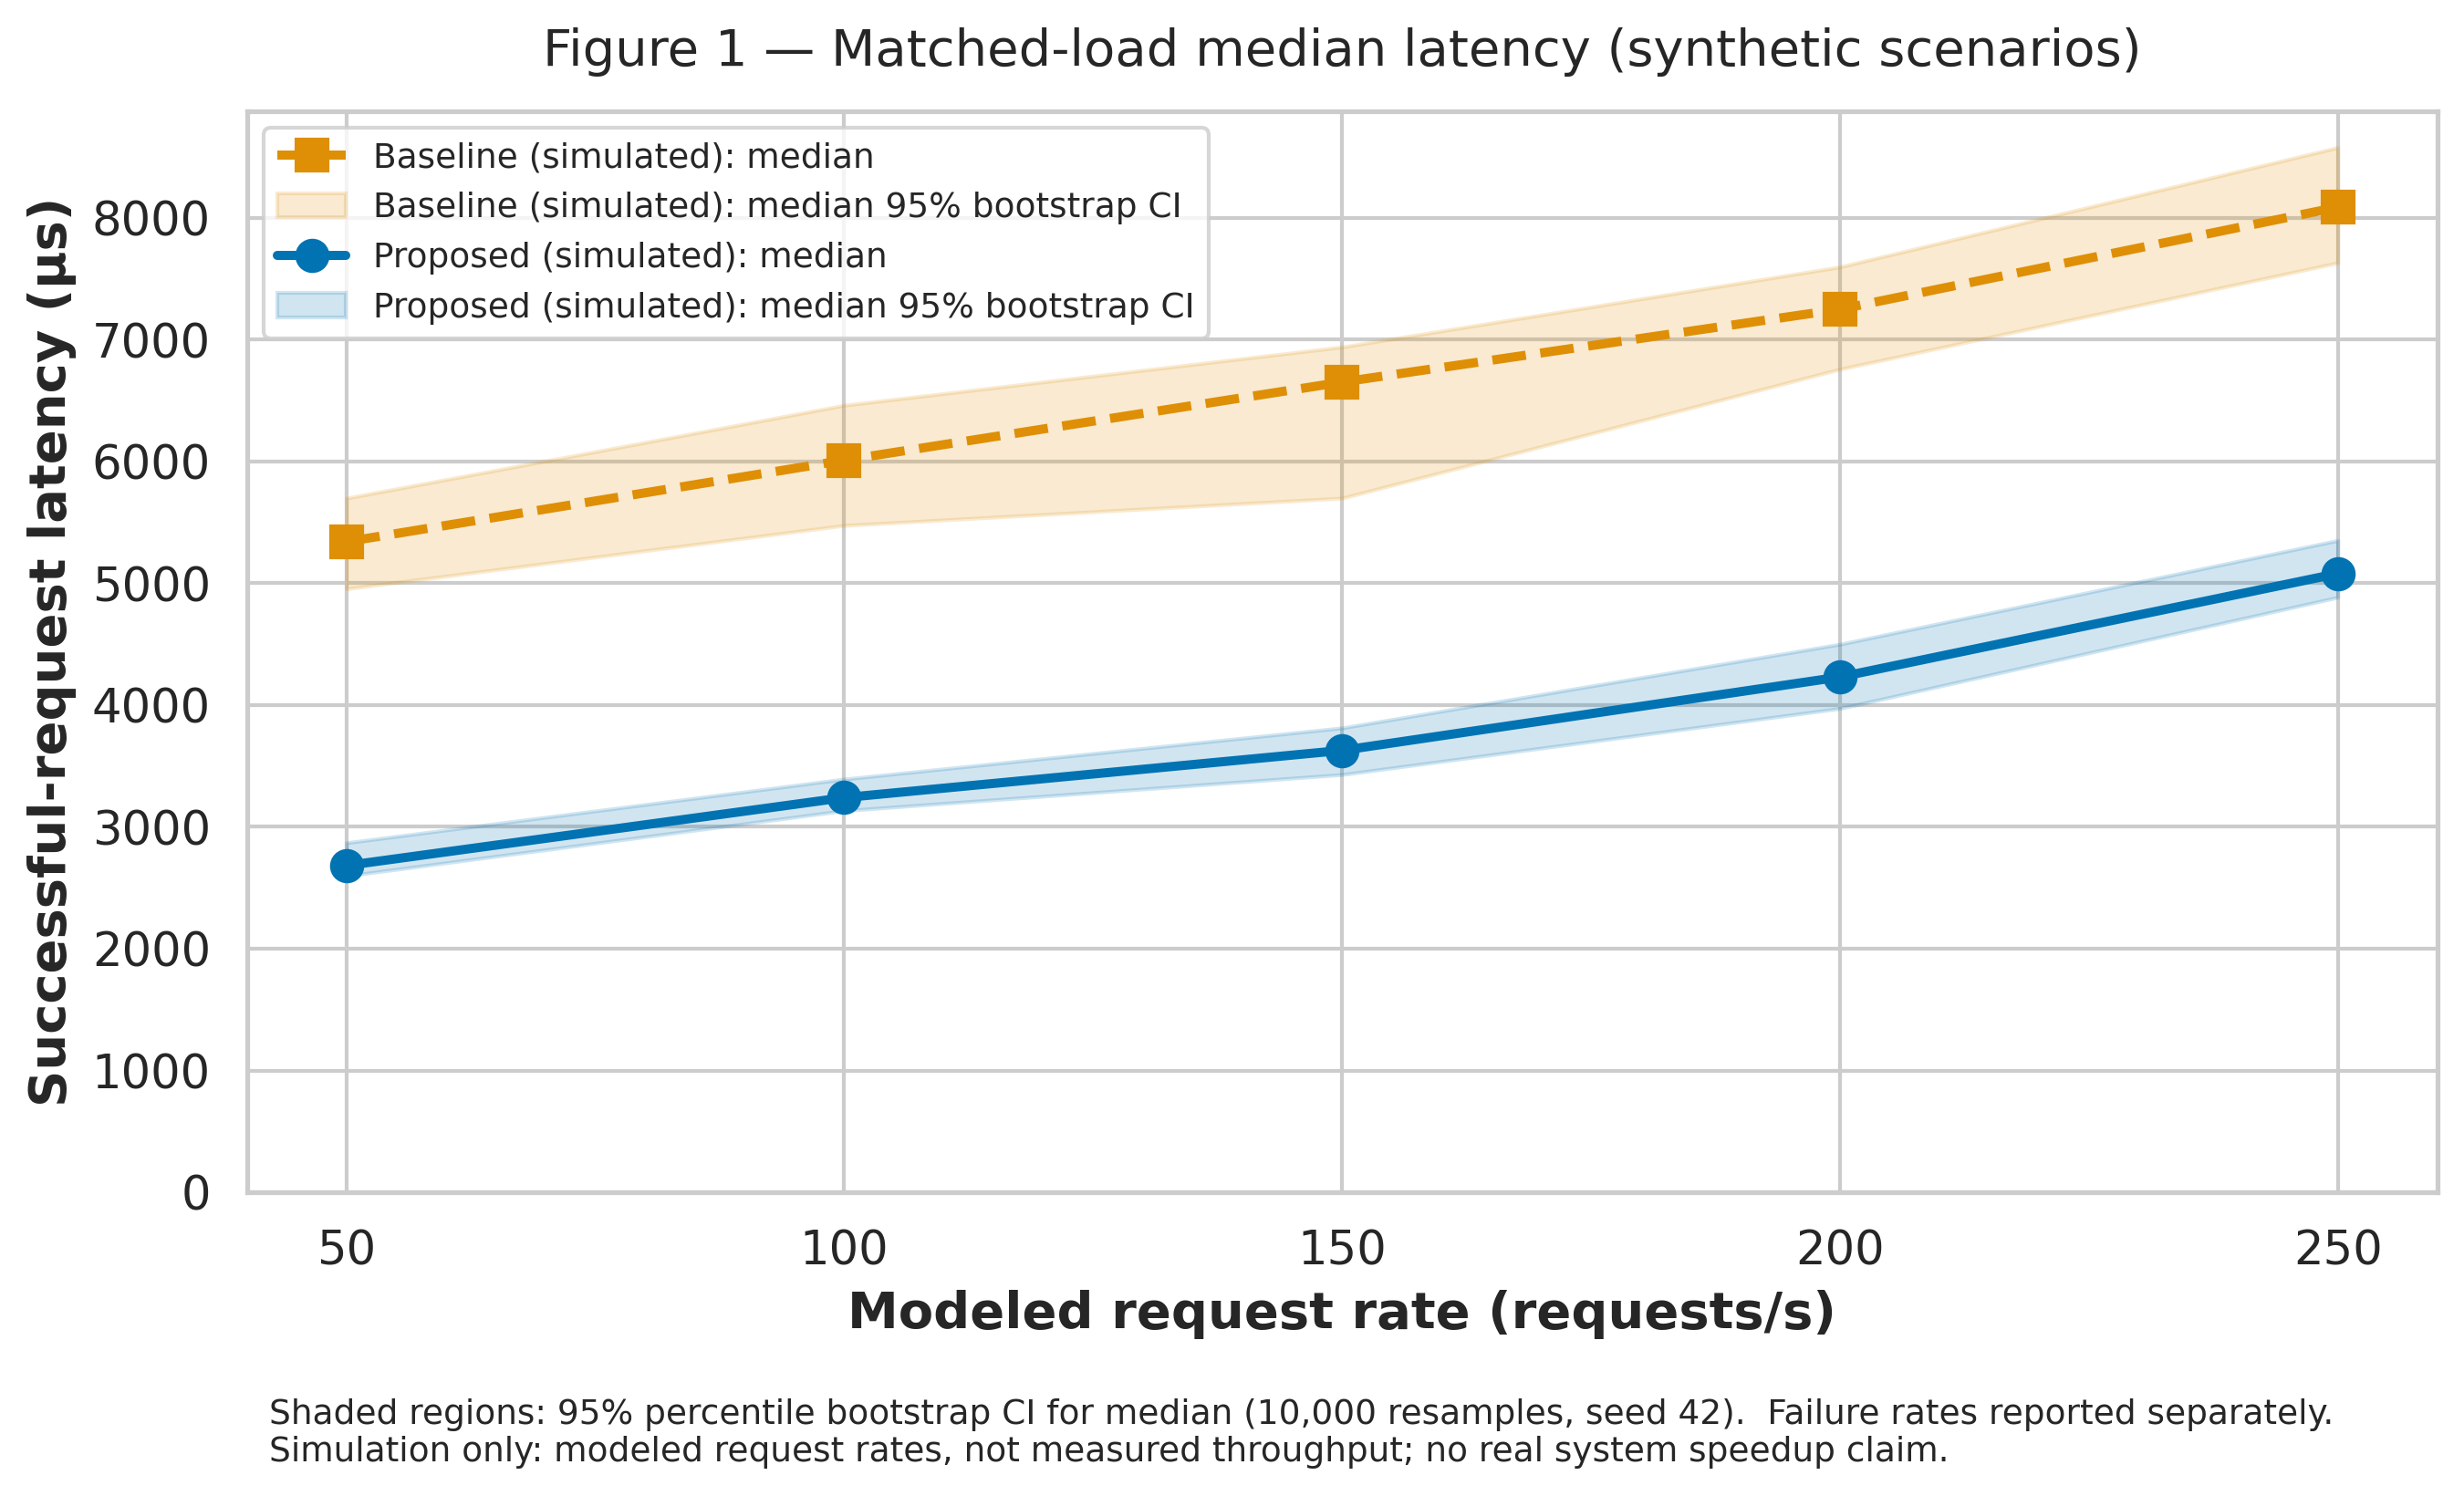

In [5]:
import matplotlib.pyplot as plt
fig1 = plot_fig1_latency_vs_load(summary, clean)
plt.close(fig1)
display(Image(filename=str(ROOT / FIGURES_DIR / 'fig1_latency_vs_load.png')))

[plot] reports/figures/fig2_distribution_boxplot.pdf


[plot] reports/figures/fig2_distribution_boxplot.png


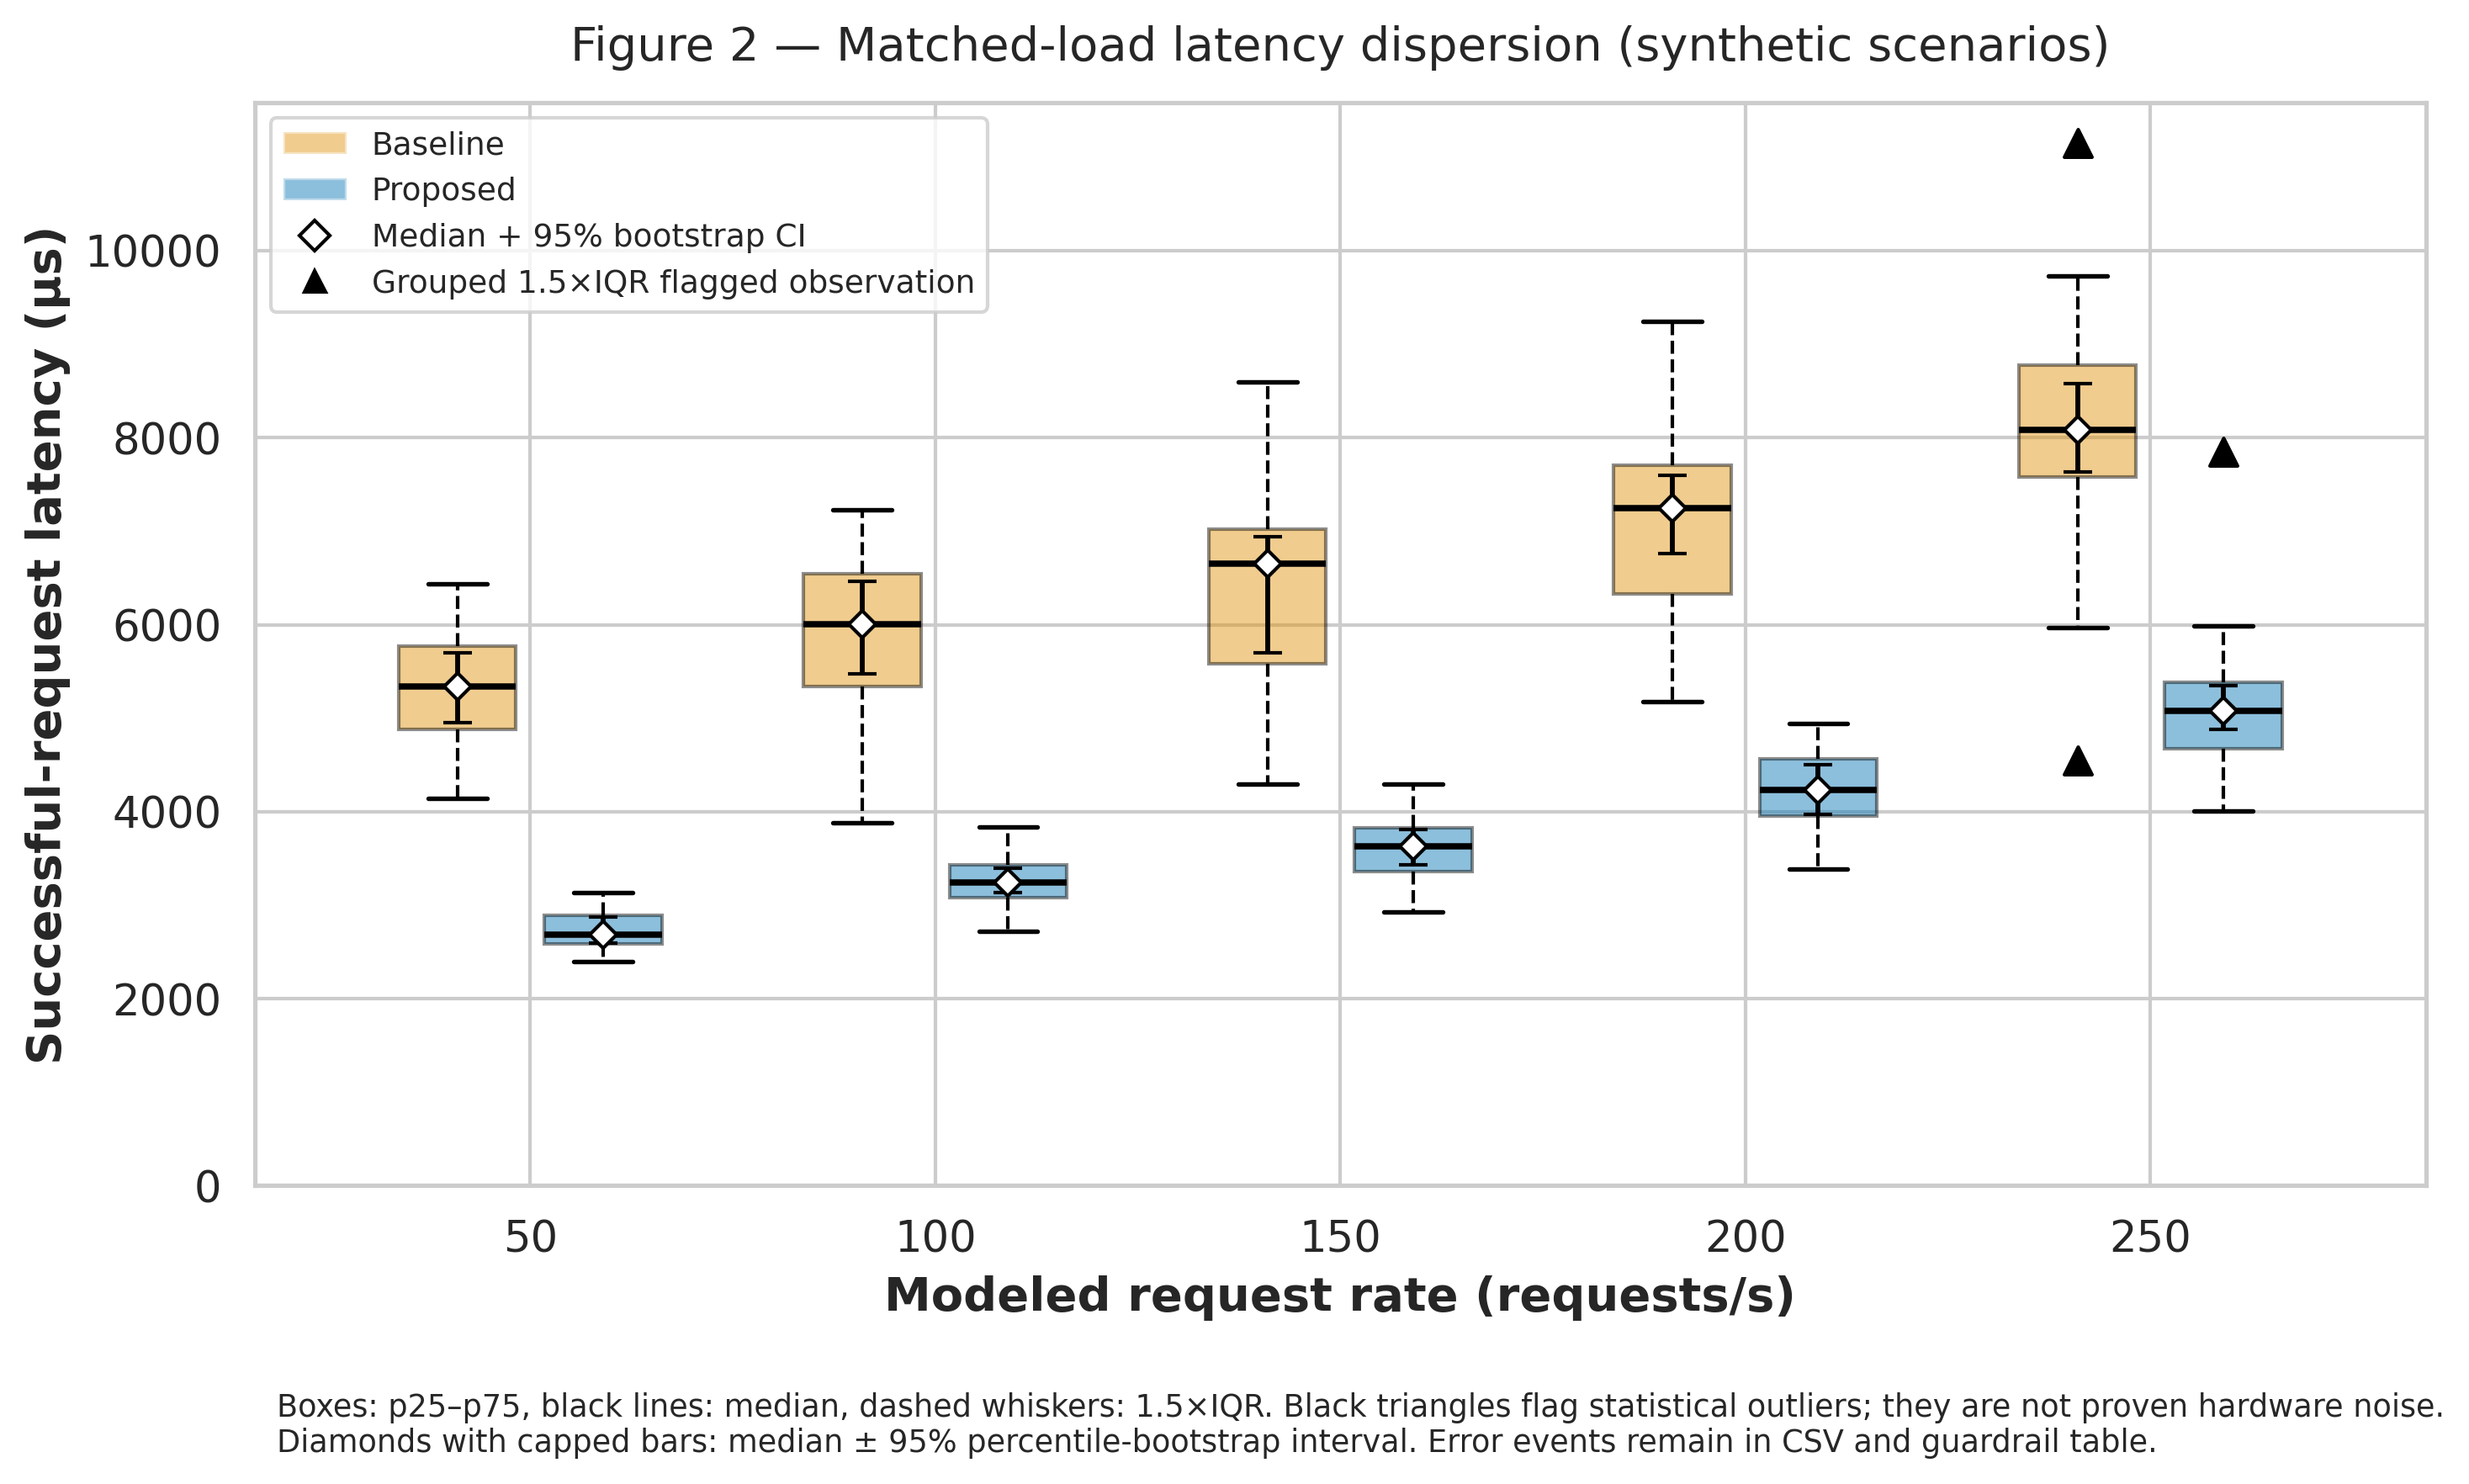

In [6]:
fig2 = plot_fig2_distribution_boxplot(clean, summary)
plt.close(fig2)
display(Image(filename=str(ROOT / FIGURES_DIR / 'fig2_distribution_boxplot.png')))

## 6. Automated output checks and research limitations

In [7]:
assert len(raw) == 260 and len(warmup) == 20 and len(evaluation) == 240
assert len(clean) == len(evaluation)  # failed attempts preserved
assert clean['status'].ne('ok').sum() == evaluation['status'].ne('ok').sum()
assert not summary['latency_median_ci95_lo'].isna().all()
assert (summary['guardrail_status'].str.startswith('BREACHED')).any()
for label in ['fig1_latency_vs_load','fig2_distribution_boxplot']:
    for ext in ['pdf','png']:
        assert (ROOT / FIGURES_DIR / f'{label}.{ext}').is_file()
print('PASS: schema, counts, preserved failures, median CIs, deliberate breach, figure exports.')
print('LIMITATION: numerical research hypotheses remain UNTESTED; live request rates were NOT measured.')

PASS: schema, counts, preserved failures, median CIs, deliberate breach, figure exports.
LIMITATION: numerical research hypotheses remain UNTESTED; live request rates were NOT measured.


### Interpretation

The lower *simulated* proposed medians are consequences of assumptions chosen in the two Gaussian generators, not proof that data collection became faster in production. Since there is a deliberate >10% failure-rate breach at one load, the proposed scenario **does not pass** the per-load reliability criterion. This synthetic software-pipeline exercise must not be interpreted as evidence that generative AI raises or reduces real commercial artists' earnings, sales, or autonomy. Full study-level primary-source extraction and appropriate outcome-specific methods would be a separate required research step.